# A Koopman model trained to forecast: multi-step loss, a spectral penalty, and compression on a split in time

Stage 4 put the Koopman autoencoder of Stage 3 on a split in time and found it worse than the mean flow from the first step, worse than dynamic mode decomposition (DMD) at every horizon, and stable or not depending on the seed. That model was trained on one-step pairs only. This notebook asks whether training it to forecast changes the picture, and whether the autoencoder's compression advantage over proper orthogonal decomposition (POD) survives a split in time.

- **Part (a): three Koopman autoencoders on the contiguous split of Stage 4** (fit on snapshots 0 to 799, per-point standardisation from the fitting period, 120 early-stopping pairs, 150 held-out starts in 800 to 949 rolled out for 50 steps): (i) Stage 3's model as it was, with its one-step loss; (ii) the same model with a multi-step loss, reconstruction plus prediction errors at 1 to 5 steps ahead with equal weights; (iii) the multi-step loss plus a spectral penalty on the operator, the sum over its eigenvalues of max(0, |λ| − 1)², with a weight chosen so that the penalty is of the order of the prediction loss at the start. Rollout error against steps ahead for the three models, DMD on 10 POD coefficients, persistence and the mean flow, on the held-out block; the eigenvalue moduli of the operator per model and seed.
- **Part (b): compression on a split in time.** The dense autoencoder of Stage 1 (latent size 10, its settings) and POD with a training basis, fitted on snapshots 0 to 799 and scored on 800 to 999, against the random-split numbers of Stage 4.

Three seeds (0, 1, 2) for every training; seed 0 is the base run. Dense networks on the Apple GPU. Errors are the notebooks' mean relative L2 error (per velocity component, then the mean over u and v). A difference is called an effect only when it is larger than the seed range.

# Stage 5 — A Koopman model trained to forecast: multi-step loss, a spectral penalty, and compression on a split in time

**Portfolio project: compress, structure, evolve — autoencoders, a VAE and a Koopman autoencoder on one flow dataset.**

Stage 4 put the Stage 3 Koopman autoencoder on a split in time and found it worse than the mean flow from the first step, worse than DMD at every horizon, and stable or not depending on the seed. That model was trained on one-step pairs only. Part (a) asks whether training it to forecast changes the picture: the same parts with (i) the one-step loss as it was, (ii) a multi-step loss (reconstruction plus the prediction errors at 1 to 5 steps ahead) and (iii) the multi-step loss plus a spectral penalty on the eigenvalues of the operator, three seeds each, rolled out 50 steps from 150 held-out starts against DMD, persistence and the mean flow. Part (b) asks whether the autoencoder's compression advantage over POD (Stages 1, 2 and 4) survives a split in time: the Stage 1 dense autoencoder and POD with a training basis, fitted on the first 800 snapshots and scored on the last 200.

**What it shows.** None of the three Koopman models beats DMD at any horizon. The multi-step loss removes the one-step model's blow-up (its error at 50 steps falls from 1.42 with a seed range of 0.62 to 1.20 with a range of 0.10) but the model settles near the mean flow (error 1) rather than on the dynamics, and DMD (0.83 to 1.10) stays below it everywhere. The spectral penalty does exactly what it says, pinning every eigenvalue on the unit circle to four decimals in every seed, without improving the forecast. On a split in time the dense autoencoder (0.96, range 0.95–0.97) is worse than POD (0.79): its random-split advantage (0.46 against 0.76) does not hold once the scored snapshots come from a later time.

**How it connects.** It reads the dataset from `../release_assets/`, copies the Stage 3 builders, the Stage 4 split, DMD and references and the Stage 1 dense builders, and reads Stage 4's device timings and tables and Stage 1's three-seed summary for the comparison columns only.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, Apple GPU, 2026-10-14, 26 minutes, longest training 230 s). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (dataset from `../release_assets/`, Stage 4 and Stage 1 tables from `../results/04_rollout_and_baselines/` and `../results/01_autoencoders_and_pod/exercises/`, tables and figures to `../results/05_koopman_trained_to_forecast/`, seed-0 models to `../models/05_koopman_trained_to_forecast/`, whose `.keras` files are not in git, as for the other stages; the 10 × 10 operators are kept as `.npy`). The part (b) figure's x labels overlap; the table above it carries the numbers.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../release_assets/G1Re100_coarse.npz")                          # release file (README)
TIMING_DIR = Path("../results/04_rollout_and_baselines")                           # device_timing_cpu.csv, device_timing_gpu.csv
EARLIER_ROLLOUT = Path("../results/04_rollout_and_baselines")                      # Stage 4's tables (read only for the comparison)
EARLIER_AE = Path("../results/01_autoencoders_and_pod/exercises")                  # Stage 1's three-seed summary (read only for the comparison)
RES = Path("../results/05_koopman_trained_to_forecast"); RES.mkdir(parents=True, exist_ok=True)
MOD = Path("../models/05_koopman_trained_to_forecast"); MOD.mkdir(parents=True, exist_ok=True)
print("data present:", DATA_FILE.exists(), "| timings present:", (TIMING_DIR / "device_timing_gpu.csv").exists(),
      "| earlier tables present:", (EARLIER_ROLLOUT / "b_rollout_summary.csv").exists(), (EARLIER_AE / "seeds_summary.csv").exists())

In [2]:
import json, time, platform
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"), "|", platform.machine())
# Device from the step timing of Stage 4 (one training step inside model.fit, batch 32, median of 30 after 10 warm-up);
# the environment is unchanged since then. The multi-step models use the same dense layers as the Koopman autoencoder.
timing = pd.concat([pd.read_csv(TIMING_DIR / "device_timing_cpu.csv"), pd.read_csv(TIMING_DIR / "device_timing_gpu.csv")])
tt = timing.pivot(index="network", columns="device", values="median_ms"); print(tt.loc[["Koopman AE (256 hidden)", "dense AE (16384-512-10)"]].round(2))
for net in ("Koopman AE (256 hidden)", "dense AE (16384-512-10)"):
    assert tt.loc[net, "gpu"] < tt.loc[net, "cpu"], net
DEVICE = "/GPU:0"; print("device for every network:", DEVICE)

data = np.load(DATA_FILE); UV = data["UV"]; xx, yy = data["x"], data["y"]
n_t, n_x, n_y, n_v = UV.shape; input_shape = (n_x, n_y, n_v)
print("UV", UV.shape)

def rel_err(v_true, v_pred):
    """The notebooks' metric: mean over snapshots of ||v - v_hat|| / ||v|| per component, then the mean over u and v."""
    e = np.linalg.norm(v_true - v_pred, axis=(1, 2)) / np.linalg.norm(v_true, axis=(1, 2))
    return float(np.mean(e))
T_START = time.time()

TensorFlow 2.18.1 | Keras 3.6.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | arm64
device                     cpu   gpu
network                             
Koopman AE (256 hidden)  10.34  9.92
dense AE (16384-512-10)  19.48  9.56
device for every network: /GPU:0


UV (1000, 128, 64, 2)


## The contiguous split, the references, and the training sequences

Copied from Stage 4: snapshots 0 to 799 are the fitting period, 800 to 999 are held out; every snapshot is standardised point by point with the mean and standard deviation of the fitting period only. DMD uses a POD basis of rank 10 from the fitting period and an operator fitted by least squares on its 799 consecutive pairs; persistence repeats the start; the mean flow predicts zero standardised fluctuation (error exactly 1). The 150 held-out starts are snapshots 800 to 949, each rolled out for 50 steps.

For the one-step model the training pairs are the 799 pairs with 120 of them (a random 15 %, Stage 4's draw) kept for early stopping. For the multi-step models each training sequence is a snapshot and its next five: 795 sequences from the fitting period, again with 120 kept for early stopping (the same random draw).

In [3]:
cut, H, K = 800, 50, 5
mu, sd = UV[:cut].mean(axis=0), UV[:cut].std(axis=0) + 1e-8
w = ((UV - mu) / sd).astype("float32")
Xa, ya = w[:cut - 1], w[1:cut]
Xt, Xv, yt, yv = train_test_split(Xa, ya, test_size=0.15, random_state=24, shuffle=True)        # one-step pairs, as in Stage 4
seq_idx = np.arange(cut - K)                                                                         # sequences s, s+1, ..., s+5 inside the fitting period
seq_t, seq_v = train_test_split(seq_idx, test_size=len(Xv), random_state=24, shuffle=True)
starts = np.arange(cut, n_t - H)
print(f"one-step pairs {len(Xa)} (training {len(Xt)}, early stopping {len(Xv)}) | sequences of {K + 1} snapshots {len(seq_idx)} (training {len(seq_t)}, early stopping {len(seq_v)}) | held-out starts {len(starts)} | horizon {H}")

# DMD on POD coefficients (rank 10), persistence and the mean flow: copied from Stage 4
d_dmd = 10
U_f, _, _ = np.linalg.svd(w[:cut].reshape((cut, -1)).T, full_matrices=False); Phi = U_f[:, :d_dmd]
A_dmd, *_ = np.linalg.lstsq(Xa.reshape((len(Xa), -1)) @ Phi, ya.reshape((len(ya), -1)) @ Phi, rcond=None)
eig_dmd = np.linalg.eigvals(A_dmd.T)
b_rows, eig_rows = [], []
a_c = w[starts].reshape((len(starts), -1)) @ Phi
for n in range(1, H + 1):
    a_c = a_c @ A_dmd; truth = w[starts + n]
    b_rows.append(dict(model="DMD (POD rank 10)", seed=-1, n=n, rel_error=rel_err(truth, (a_c @ Phi.T).reshape(truth.shape))))
    b_rows.append(dict(model="persistence", seed=-1, n=n, rel_error=rel_err(truth, w[starts])))
    b_rows.append(dict(model="mean flow (zero fluctuation)", seed=-1, n=n, rel_error=rel_err(truth, np.zeros_like(truth))))
eig_rows.extend(dict(model="DMD (POD rank 10)", seed=-1, re=float(l.real), im=float(l.imag), modulus=float(abs(l))) for l in eig_dmd)
print("DMD |eigenvalues|:", np.round(np.sort(np.abs(eig_dmd))[::-1], 4))

one-step pairs 799 (training 679, early stopping 120) | sequences of 6 snapshots 795 (training 675, early stopping 120) | held-out starts 150 | horizon 50


DMD |eigenvalues|: [0.9978 0.9978 0.9961 0.9961 0.9929 0.9929 0.9893 0.9893 0.9875 0.9875]


## The three Koopman autoencoders

All three share Stage 3's parts, copied unchanged: a dense encoder (16,384 → 256 → 10), a linear operator A (10 × 10, no bias) and a dense decoder (10 → 256 → 16,384), Adam at 1e-3, batch 32, up to 600 epochs, early stopping with patience 20 on the early-stopping loss and learning-rate halving after 8 epochs without improvement.

- **(i) one-step loss**: Stage 3's model as it was: mean squared error of the reconstruction plus mean squared error of the one-step prediction, equal weights.
- **(ii) multi-step loss**: reconstruction plus the prediction errors at 1, 2, 3, 4 and 5 steps ahead (the latent state advanced by A once per step, decoded at every step), six mean squared errors with equal weights.
- **(iii) multi-step loss plus a spectral penalty**: the loss of (ii) plus w · Σ_i max(0, |λ_i(A)| − 1)², the eigenvalues of A recomputed at every training step. The weight w is set below from the prediction loss at the start.

In [4]:
# Stage 3's builders, copied unchanged
def k_dense_encoder(input_shape, latent_dim, hidden_units=512, activation="relu"):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    return tf.keras.Model(inputs, tf.keras.layers.Dense(latent_dim)(x), name="dense_encoder")

def k_dense_decoder(output_shape, latent_dim, hidden_units=512, activation="relu"):
    n_x, n_y, n_v = output_shape
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dense(n_x * n_y * n_v)(x)
    return tf.keras.Model(latent_inputs, tf.keras.layers.Reshape(output_shape)(x), name="dense_decoder")

def create_koopman_operator(latent_dim):
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    return tf.keras.Model(latent_inputs, tf.keras.layers.Dense(latent_dim, use_bias=False, name="A")(latent_inputs), name="koopman_operator")

def create_koopman_autoencoder(input_shape, latent_dim, hidden_units=256, activation="relu", learning_rate=1e-3):
    encoder = k_dense_encoder(input_shape, latent_dim=latent_dim, hidden_units=hidden_units, activation=activation)
    koopman_operator = create_koopman_operator(latent_dim)
    decoder = k_dense_decoder(input_shape, latent_dim=latent_dim, hidden_units=hidden_units, activation=activation)
    inputs = tf.keras.layers.Input(shape=input_shape)
    encoded = encoder(inputs)
    model = tf.keras.Model(inputs, [decoder(encoded), decoder(koopman_operator(encoded))], name="Koopman_Autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss=["mse", "mse"], loss_weights=[1.0, 1.0])
    return model, encoder, koopman_operator, decoder

# The multi-step model: the same three parts, a custom training step with the six-term loss and the optional spectral penalty
class MultiStepKoopman(tf.keras.Model):
    def __init__(self, input_shape, latent_dim=10, hidden_units=256, steps=5, spectral_weight=0.0, **kw):
        super().__init__(**kw)
        self.encoder = k_dense_encoder(input_shape, latent_dim, hidden_units)
        self.operator = create_koopman_operator(latent_dim)
        self.decoder = k_dense_decoder(input_shape, latent_dim, hidden_units)
        self.steps, self.spectral_weight = steps, spectral_weight
        self.trackers = {k: tf.keras.metrics.Mean(name=k) for k in ("loss", "recon", "pred", "penalty")}
    @property
    def metrics(self): return list(self.trackers.values())
    def call(self, x): return self.decoder(self.encoder(x))
    def penalty(self):
        A = self.operator.get_layer("A").kernel                      # z_next = z @ A
        lam, _ = tf.linalg.eig(tf.transpose(A))
        return tf.reduce_sum(tf.square(tf.nn.relu(tf.abs(lam) - 1.0)))
    def losses_on(self, x_seq):                                      # x_seq: (batch, steps + 1, n_x, n_y, n_v)
        z = self.encoder(x_seq[:, 0]); recon = tf.reduce_mean(tf.square(self.decoder(z) - x_seq[:, 0])); pred = 0.0
        for n in range(1, self.steps + 1):
            z = self.operator(z); pred += tf.reduce_mean(tf.square(self.decoder(z) - x_seq[:, n]))
        pen = self.penalty()
        return recon, pred, pen, recon + pred + self.spectral_weight * pen
    def train_step(self, data):
        x_seq = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            recon, pred, pen, total = self.losses_on(x_seq)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        for k, v in zip(("loss", "recon", "pred", "penalty"), (total, recon, pred, pen)): self.trackers[k].update_state(v)
        return {k: m.result() for k, m in self.trackers.items()}
    def test_step(self, data):
        x_seq = data[0] if isinstance(data, (tuple, list)) else data
        recon, pred, pen, total = self.losses_on(x_seq)
        for k, v in zip(("loss", "recon", "pred", "penalty"), (total, recon, pred, pen)): self.trackers[k].update_state(v)
        return {k: m.result() for k, m in self.trackers.items()}

SEQ = np.stack([w[s:s + K + 1] for s in seq_idx])            # (795, 6, 128, 64, 2)
SEQ_t, SEQ_v = SEQ[seq_t], SEQ[seq_v]
print("training sequences", SEQ_t.shape, "| early-stopping sequences", SEQ_v.shape)

def callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6)]

training sequences (675, 6, 128, 64, 2) | early-stopping sequences (120, 6, 128, 64, 2)


### Choosing the weight of the spectral penalty

At initialisation the random operator's eigenvalues sit close to the unit circle and the penalty is a tiny fraction of the prediction loss, so matching the two directly would tie the weight to an accident of the initial weights. Instead I measure the prediction loss of the untrained model (seed 0) on the training sequences, L₀, and set w = L₀ / δ² with δ = 0.05: the penalty equals the initial prediction loss as soon as one eigenvalue sits 0.05 outside the unit circle. The excursions of the one-step models in Stages 3 and 4 were 0.011 to 0.069, so an excursion of that size costs as much as the whole prediction loss at the start.

In [5]:
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(0)
with tf.device(DEVICE):
    m0 = MultiStepKoopman(input_shape, 10, 256, K, 0.0); m0.compile(optimizer=tf.keras.optimizers.Adam(1e-3))
    recon0, pred0, pen0, _ = m0.losses_on(tf.constant(SEQ_t[:256]))
L0, P0 = float(pred0), float(pen0); DELTA = 0.05; W_SPEC = L0 / DELTA ** 2
lam0 = np.linalg.eigvals(m0.operator.get_layer("A").get_weights()[0].T)
print(f"untrained model, seed 0: reconstruction loss {float(recon0):.4f}, prediction loss (sum of 5 steps) L0 = {L0:.4f}, penalty {P0:.4f}, "
      f"largest |eigenvalue| {np.abs(lam0).max():.3f}")
print(f"spectral weight w = L0 / {DELTA}^2 = {W_SPEC:.1f}")
json.dump(dict(L0=L0, P0=P0, delta=DELTA, w=W_SPEC, max_modulus_init=float(np.abs(lam0).max())), open(RES / "a_spectral_weight.json", "w"), indent=1)
del m0

2026-10-14 21:59:11.410323: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-14 21:59:11.410349: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-14 21:59:11.410363: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1792029551.410377 57899759 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792029551.410396 57899759 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


untrained model, seed 0: reconstruction loss 1.0015, prediction loss (sum of 5 steps) L0 = 4.9822, penalty 0.0011, largest |eigenvalue| 1.023
spectral weight w = L0 / 0.05^2 = 1992.9


## Part (a): training and rollout, one cell per seed

Rollout: encode the start once, advance the latent state with A once per step, decode at every step; error against the true snapshot at each of the 50 steps, averaged over the 150 starts.

In [6]:
MODELS_A = ("(i) one-step loss", "(ii) multi-step loss", "(iii) multi-step + spectral penalty")
k_info = []
def rollout_and_record(name, seed, enc, A, dec):
    lam = np.linalg.eigvals(A.T)
    eig_rows.extend(dict(model=name, seed=seed, re=float(l.real), im=float(l.imag), modulus=float(abs(l))) for l in lam)
    z = enc.predict(w[starts], verbose=0, batch_size=256)
    for n in range(1, H + 1):
        z = z @ A; truth = w[starts + n]
        b_rows.append(dict(model=name, seed=seed, n=n, rel_error=rel_err(truth, dec.predict(z, verbose=0, batch_size=256))))
    return float(np.abs(lam).max())

def run_a(seed):
    for name in MODELS_A:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed); t0 = time.perf_counter()
        with tf.device(DEVICE):
            if name.startswith("(i)"):
                m, enc, op, dec = create_koopman_autoencoder(input_shape, 10)
                h = m.fit(Xt, [Xt, yt], validation_data=(Xv, [Xv, yv]), epochs=600, batch_size=32, verbose=0, callbacks=callbacks())
                A = op.get_layer("A").get_weights()[0]; extra = {}
            else:
                m = MultiStepKoopman(input_shape, 10, 256, K, W_SPEC if name.startswith("(iii)") else 0.0); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3))
                h = m.fit(SEQ_t, validation_data=SEQ_v, epochs=600, batch_size=32, verbose=0, callbacks=callbacks())
                enc, dec, A = m.encoder, m.decoder, m.operator.get_layer("A").get_weights()[0]
                extra = dict(final_recon=float(h.history["recon"][-1]), final_pred=float(h.history["pred"][-1]), final_penalty=float(h.history["penalty"][-1]))
            train_s = time.perf_counter() - t0
            maxmod = rollout_and_record(name, seed, enc, A, dec)
            if seed == 0:
                tag = {"(i) one-step loss": "one_step", "(ii) multi-step loss": "multi_step", "(iii) multi-step + spectral penalty": "multi_step_spectral"}[name]
                enc.save(MOD / f"koopman_{tag}_encoder_seed0.keras"); dec.save(MOD / f"koopman_{tag}_decoder_seed0.keras"); np.save(MOD / f"koopman_{tag}_A_seed0.npy", A)
        k_info.append(dict(model=name, seed=seed, epochs=len(h.history["loss"]), best_epoch=int(np.argmin(h.history["val_loss"])) + 1, train_s=round(train_s, 1),
                           final_val_loss=float(min(h.history["val_loss"])), max_modulus=maxmod, **extra))
        e = [r["rel_error"] for r in b_rows if r["model"] == name and r["seed"] == seed]
        print(k_info[-1], "| n = 1 / 5 / 10 / 50:", [round(e[i - 1], 4) for i in (1, 5, 10, 50)], flush=True)

In [7]:
run_a(0)  # seed 0, the base run

2026-10-14 21:59:12.179281: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


{'model': '(i) one-step loss', 'seed': 0, 'epochs': 216, 'best_epoch': 196, 'train_s': 59.6, 'final_val_loss': 0.49766871333122253, 'max_modulus': 0.9895129799842834} | n = 1 / 5 / 10 / 50: [1.0152, 1.4255, 1.1183, 1.0755]


{'model': '(ii) multi-step loss', 'seed': 0, 'epochs': 260, 'best_epoch': 240, 'train_s': 98.7, 'final_val_loss': 2.098320245742798, 'max_modulus': 1.0162558555603027, 'final_recon': 0.17646469175815582, 'final_pred': 0.8396584987640381, 'final_penalty': 0.00028395873960107565} | n = 1 / 5 / 10 / 50: [0.9983, 1.0147, 1.0943, 1.2348]


{'model': '(iii) multi-step + spectral penalty', 'seed': 0, 'epochs': 176, 'best_epoch': 156, 'train_s': 67.4, 'final_val_loss': 2.4885706901550293, 'max_modulus': 0.9999462366104126, 'final_recon': 0.21384195983409882, 'final_pred': 1.1768670082092285, 'final_penalty': 1.1943189492935602e-10} | n = 1 / 5 / 10 / 50: [0.9961, 1.0136, 1.0927, 1.1821]


In [8]:
run_a(1)  # seed 1

{'model': '(i) one-step loss', 'seed': 1, 'epochs': 231, 'best_epoch': 211, 'train_s': 65.5, 'final_val_loss': 0.4898696839809418, 'max_modulus': 1.0163486003875732} | n = 1 / 5 / 10 / 50: [1.0258, 1.2938, 1.5085, 1.4938]


{'model': '(ii) multi-step loss', 'seed': 1, 'epochs': 341, 'best_epoch': 321, 'train_s': 129.7, 'final_val_loss': 1.2442476749420166, 'max_modulus': 1.0090415477752686, 'final_recon': 0.12778469920158386, 'final_pred': 0.5450649261474609, 'final_penalty': 0.00016676490486133844} | n = 1 / 5 / 10 / 50: [1.0255, 1.0382, 1.0886, 1.2404]


{'model': '(iii) multi-step + spectral penalty', 'seed': 1, 'epochs': 600, 'best_epoch': 599, 'train_s': 229.7, 'final_val_loss': 1.577357530593872, 'max_modulus': 0.9998111128807068, 'final_recon': 0.15496307611465454, 'final_pred': 0.6928220987319946, 'final_penalty': 0.0} | n = 1 / 5 / 10 / 50: [1.0031, 1.017, 1.0839, 1.0745]


In [9]:
run_a(2)  # seed 2

{'model': '(i) one-step loss', 'seed': 2, 'epochs': 187, 'best_epoch': 167, 'train_s': 54.9, 'final_val_loss': 0.552838921546936, 'max_modulus': 1.010707139968872} | n = 1 / 5 / 10 / 50: [0.9992, 1.0827, 1.2689, 1.7002]


{'model': '(ii) multi-step loss', 'seed': 2, 'epochs': 333, 'best_epoch': 313, 'train_s': 127.4, 'final_val_loss': 1.5761995315551758, 'max_modulus': 1.0061296224594116, 'final_recon': 0.1479530781507492, 'final_pred': 0.6651521325111389, 'final_penalty': 4.243953662808053e-05} | n = 1 / 5 / 10 / 50: [1.0159, 1.0299, 1.0827, 1.1376]


{'model': '(iii) multi-step + spectral penalty', 'seed': 2, 'epochs': 468, 'best_epoch': 448, 'train_s': 182.5, 'final_val_loss': 1.919896125793457, 'max_modulus': 1.0000073909759521, 'final_recon': 0.1756175458431244, 'final_pred': 0.8643603920936584, 'final_penalty': 3.666012979297584e-11} | n = 1 / 5 / 10 / 50: [0.9936, 0.9875, 1.0394, 1.0768]


### Part (a) table and figure

A model **beats DMD at a horizon** when all three seeds are below DMD's error there and the mean improvement is larger than the seed range (maximum minus minimum). A model is **stable in a seed** when every eigenvalue of its operator has modulus at most 1.

Mean relative error at n steps ahead (networks: mean of 3 seeds)
n                                        1       2       5       10      20      50
model                                                                              
(i) one-step loss                    1.0134  1.2293  1.2673  1.2986  1.3694  1.4232
(ii) multi-step loss                 1.0132  1.0125  1.0276  1.0885  1.1547  1.2043
(iii) multi-step + spectral penalty  0.9976  0.9934  1.0060  1.0720  1.1951  1.1111
DMD (POD rank 10)                    0.8334  0.8399  0.8666  0.9127  0.9764  1.0963
persistence                          0.4006  0.7327  1.3050  1.5867  1.2061  1.3366
mean flow (zero fluctuation)         1.0000  1.0000  1.0000  1.0000  1.0000  1.0000

Seed range (max − min)
n                                        1       2       5       10      20      50
model                                                                              
(i) one-step loss                    0.0266  0.2866  0.3428  0.3902  0.

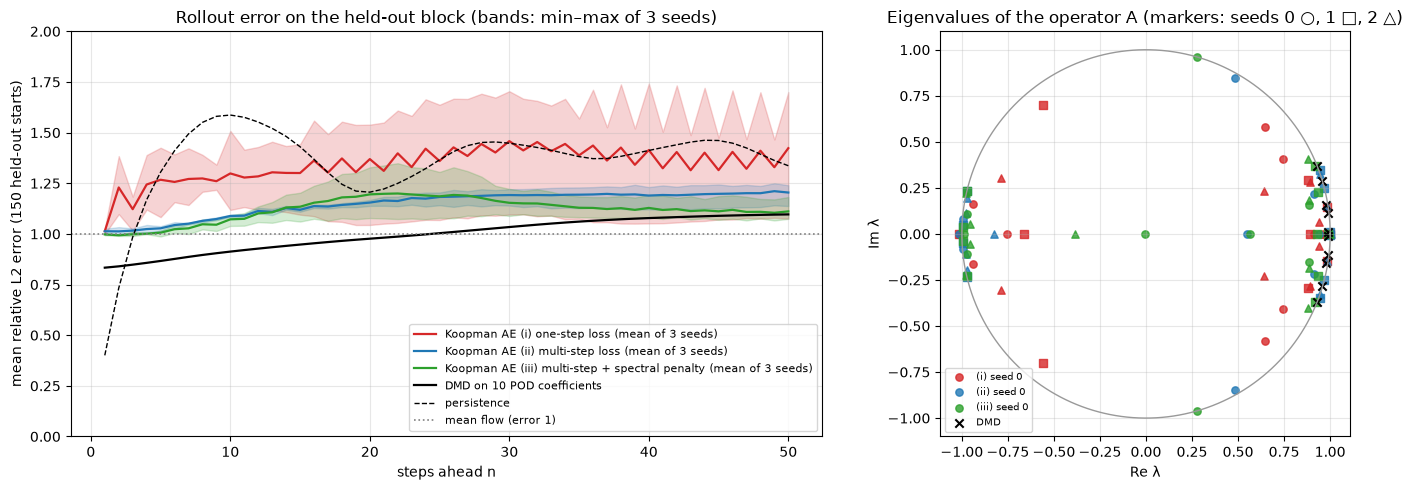

In [10]:
b = pd.DataFrame(b_rows); b.to_csv(RES / "a_rollout_runs.csv", index=False)
ki = pd.DataFrame(k_info); ki.to_csv(RES / "a_training.csv", index=False)
eig = pd.DataFrame(eig_rows); eig.to_csv(RES / "a_eigenvalues.csv", index=False)
bs = b.groupby(["model", "n"]).rel_error.agg(["mean", "min", "max"]).reset_index(); bs.to_csv(RES / "a_rollout_summary.csv", index=False)
SHOW = (1, 2, 5, 10, 20, 50)
tab = bs[bs.n.isin(SHOW)].pivot(index="model", columns="n", values="mean").reindex(list(MODELS_A) + ["DMD (POD rank 10)", "persistence", "mean flow (zero fluctuation)"])
tab.to_csv(RES / "a_table.csv"); print("Mean relative error at n steps ahead (networks: mean of 3 seeds)"); print(tab.round(4).to_string())
rng_tab = bs[bs.n.isin(SHOW)].assign(rng=lambda d: d["max"] - d["min"]).pivot(index="model", columns="n", values="rng").reindex(list(MODELS_A))
print("\nSeed range (max − min)"); print(rng_tab.round(4).to_string())

dmd = bs[bs.model == "DMD (POD rank 10)"].set_index("n")["mean"]
verdict_rows = []
for name in MODELS_A:
    s = bs[bs.model == name].set_index("n")
    beats = [int(n) for n in s.index if (s.loc[n, "max"] < dmd[n]) and ((dmd[n] - s.loc[n, "mean"]) > (s.loc[n, "max"] - s.loc[n, "min"]))]
    below_mean_flow = [int(n) for n in s.index if s.loc[n, "max"] < 1.0]
    mods = eig[eig.model == name].groupby("seed").modulus.max()
    verdict_rows.append(dict(model=name, horizons_beating_dmd=beats, first_horizon_beating_dmd=(beats[0] if beats else None), n_horizons_beating_dmd=len(beats),
                             horizons_below_mean_flow_all_seeds=len(below_mean_flow), max_modulus_per_seed=[round(float(v), 4) for v in mods.values],
                             stable_every_seed=bool((mods <= 1.0).all()), stable_seeds=int((mods <= 1.0).sum())))
v = pd.DataFrame(verdict_rows); v.to_csv(RES / "a_verdict.csv", index=False); print("\n" + v.to_string(index=False))
eig_sum = eig.groupby(["model", "seed"]).modulus.agg(max_modulus="max", n_outside=lambda s: int((s > 1).sum())).reset_index(); eig_sum.to_csv(RES / "a_eigen_summary.csv", index=False)
print("\nResult (a): " + "; ".join(f"{r.model}: beats DMD at {r.n_horizons_beating_dmd} of 50 horizons" + (f" (first n = {int(r.first_horizon_beating_dmd)})" if pd.notna(r.first_horizon_beating_dmd) else "")
      + f", stable in {r.stable_seeds} of 3 seeds" for r in v.itertuples()))

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.6, 1]))
cols = {"(i) one-step loss": "#d62728", "(ii) multi-step loss": "#1f77b4", "(iii) multi-step + spectral penalty": "#2ca02c"}
ns = np.arange(1, H + 1)
for name, c in cols.items():
    s = bs[bs.model == name]; ax[0].plot(s.n, s["mean"], color=c, lw=1.6, label=f"Koopman AE {name} (mean of 3 seeds)"); ax[0].fill_between(s.n, s["min"], s["max"], color=c, alpha=0.2)
ax[0].plot(ns, dmd.values, "k-", lw=1.6, label="DMD on 10 POD coefficients"); ax[0].plot(ns, bs[bs.model == "persistence"]["mean"].values, "k--", lw=1, label="persistence")
ax[0].axhline(1.0, color="0.5", ls=":", lw=1.2, label="mean flow (error 1)")
ax[0].set_xlabel("steps ahead n"); ax[0].set_ylabel("mean relative L2 error (150 held-out starts)"); ax[0].set_ylim(0, max(2.0, float(bs["max"].quantile(0.98)))); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[0].set_title("Rollout error on the held-out block (bands: min–max of 3 seeds)")
th = np.linspace(0, 2 * np.pi, 200); ax[1].plot(np.cos(th), np.sin(th), color="0.6", lw=1)
for name, c in cols.items():
    for seed, mk in zip((0, 1, 2), ("o", "s", "^")):
        e = eig[(eig.model == name) & (eig.seed == seed)]; ax[1].scatter(e.re, e.im, color=c, marker=mk, s=28, alpha=0.8, label=f"{name.split(')')[0]}) seed {seed}" if seed == 0 else None)
e = eig[eig.model == "DMD (POD rank 10)"]; ax[1].scatter(e.re, e.im, color="k", marker="x", s=36, label="DMD")
ax[1].set_aspect("equal"); ax[1].set_xlabel("Re λ"); ax[1].set_ylabel("Im λ"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=7, loc="lower left")
ax[1].set_title("Eigenvalues of the operator A (markers: seeds 0 ○, 1 □, 2 △)")
fig.tight_layout(); fig.savefig(RES / "a_rollout_eigenvalues.png", dpi=130); plt.show()

## Part (b): compression on a split in time

Stage 1's dense autoencoder (16,384 → 512 → 10 → 512 → 16,384, no dropout; Adam 1e-3, mean squared error, batch 32, up to 600 epochs, early stopping patience 20, learning-rate halving patience 8), its builders copied below. As in that stage, the time-mean field is removed and nothing is scaled, but here the mean comes from snapshots 0 to 799 only. The autoencoder is fitted on 680 of those 800 snapshots with the other 120 (the same random draw as above) for early stopping; POD takes its basis of 10 modes from all 800. Both are scored on snapshots 800 to 999. The random-split numbers are Stage 4's (POD with a training basis, and its dense autoencoder trained with Stage 2's builder and budget) and Stage 1's own three seeds.

In [11]:
# Stage 1's builders, copied unchanged
def create_dense_encoder(input_shape, latent_dim, hidden_units=512, activation="relu"):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    latent = tf.keras.layers.Dense(latent_dim)(x)
    return tf.keras.Model(inputs, latent, name="dense_encoder")

def create_dense_decoder(output_shape, latent_dim, hidden_units=512, activation="relu", dropout_rate=0.2):
    n_x, n_y, n_v = output_shape
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dense(n_x * n_y * n_v)(x)
    return tf.keras.Model(latent_inputs, tf.keras.layers.Reshape(output_shape)(x), name="dense_decoder")

v_mean = UV[:cut].mean(axis=0); vv = (UV - v_mean).astype("float32")
fit_idx, es_idx = train_test_split(np.arange(cut), test_size=120, random_state=24, shuffle=True)
v_fit, v_es, v_score = vv[fit_idx], vv[es_idx], vv[cut:]
U_b, _, _ = np.linalg.svd(vv[:cut].reshape((cut, -1)).T, full_matrices=False); P = U_b[:, :10]
X_s = v_score.reshape((len(v_score), -1)); pod_time = rel_err(v_score, (X_s @ P @ P.T).reshape(v_score.shape))
print(f"POD, 10 modes from snapshots 0–799, scored on 800–999: {pod_time:.4f}")

bb_rows = []
def run_b(seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed); t0 = time.perf_counter()
    with tf.device(DEVICE):
        enc, dec = create_dense_encoder(input_shape, 10), create_dense_decoder(input_shape, 10)
        i = tf.keras.layers.Input(shape=input_shape); ae = tf.keras.Model(i, dec(enc(i)), name="dense_autoencoder")
        ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
        h = ae.fit(v_fit, v_fit, validation_data=(v_es, v_es), epochs=600, batch_size=32, verbose=0, callbacks=callbacks())
        err = rel_err(v_score, ae.predict(v_score, verbose=0, batch_size=256))
        if seed == 0: ae.save(MOD / "dense_ae_d10_time_split_seed0.keras")
    bb_rows.append(dict(model="dense AE (d = 10), time split", seed=seed, rel_error=err, epochs=len(h.history["loss"]), train_s=round(time.perf_counter() - t0, 1)))
    print(bb_rows[-1], flush=True)

POD, 10 modes from snapshots 0–799, scored on 800–999: 0.7875


In [12]:
run_b(0)  # seed 0, the base run

{'model': 'dense AE (d = 10), time split', 'seed': 0, 'rel_error': 0.9525677561759949, 'epochs': 600, 'train_s': 167.0}


In [13]:
run_b(1)  # seed 1

{'model': 'dense AE (d = 10), time split', 'seed': 1, 'rel_error': 0.9653544425964355, 'epochs': 600, 'train_s': 165.6}


In [14]:
run_b(2)  # seed 2

{'model': 'dense AE (d = 10), time split', 'seed': 2, 'rel_error': 0.9653875827789307, 'epochs': 600, 'train_s': 166.0}


                          split                                                    model   mean    min    max                                  source
time (fit 0–799, score 800–999)                            POD, 10 modes, training basis 0.7875    NaN    NaN                                this run
time (fit 0–799, score 800–999)                                         dense AE, d = 10 0.9611 0.9526 0.9654                       this run, 3 seeds
             random (800 / 200)                            POD, 10 modes, training basis 0.7572    NaN    NaN              Stage 4, earlier run
             random (800 / 200)   dense AE, d = 10 (Stage 2 builder, 150-epoch budget) 0.4992 0.4786 0.5131     Stage 4, earlier run, 3 seeds
             random (800 / 200) dense AE, d = 10 (Stage 1 builder, 600 epochs) 0.4649 0.4578 0.4756 Stage 1, earlier run, 3 seeds

Result (b): on the split in time the dense AE scores 0.9611 [0.9526, 0.9654] against POD 0.7875; advantage -0.1736 vs seed range 0.01

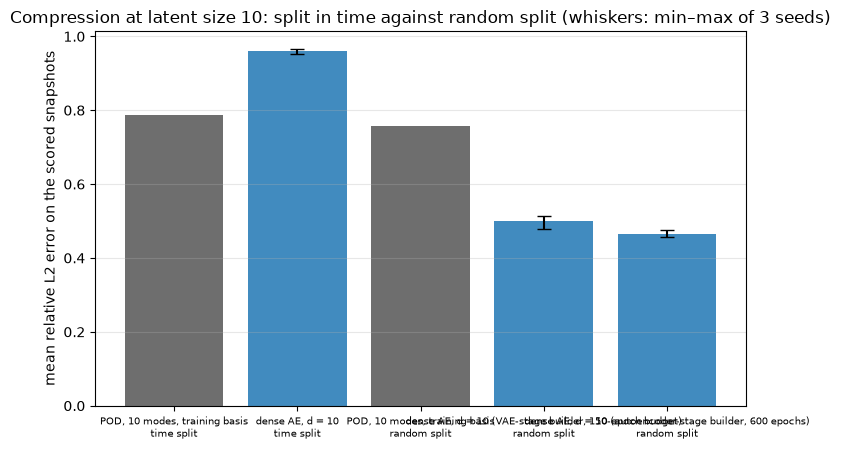

In [15]:
bb = pd.DataFrame(bb_rows); bb.to_csv(RES / "b_runs.csv", index=False)
ae_t = bb.rel_error
rows_b = [dict(split="time (fit 0–799, score 800–999)", model="POD, 10 modes, training basis", mean=pod_time, min=np.nan, max=np.nan, source="this run"),
          dict(split="time (fit 0–799, score 800–999)", model="dense AE, d = 10", mean=ae_t.mean(), min=ae_t.min(), max=ae_t.max(), source="this run, 3 seeds")]
try:
    ea = pd.read_csv(EARLIER_ROLLOUT / "a_table.csv").set_index("d"); es = pd.read_csv(EARLIER_ROLLOUT / "a_summary.csv")
    r10 = es[(es.model == "dense AE") & (es.d == 10)].iloc[0]
    rows_b.append(dict(split="random (800 / 200)", model="POD, 10 modes, training basis", mean=float(ea.loc[10, "POD, training basis, validation"]), min=np.nan, max=np.nan, source="Stage 4, earlier run"))
    rows_b.append(dict(split="random (800 / 200)", model="dense AE, d = 10 (Stage 2 builder, 150-epoch budget)", mean=float(r10["mean"]), min=float(r10["min"]), max=float(r10["max"]), source="Stage 4, earlier run, 3 seeds"))
    e1 = pd.read_csv(EARLIER_AE / "seeds_summary.csv"); d1 = e1[e1.config == "dense AE, d=10"].iloc[0]
    rows_b.append(dict(split="random (800 / 200)", model="dense AE, d = 10 (Stage 1 builder, 600 epochs)", mean=float(d1["mean"]), min=float(d1["min"]), max=float(d1["max"]), source="Stage 1, earlier run, 3 seeds"))
except Exception as e:
    print("earlier tables not read:", e)
tb = pd.DataFrame(rows_b); tb.to_csv(RES / "b_table.csv", index=False); print(tb.round(4).to_string(index=False))
gain = pod_time - ae_t.mean(); rng_ = ae_t.max() - ae_t.min()
holds = bool((ae_t.max() < pod_time) and (gain > rng_))
print(f"\nResult (b): on the split in time the dense AE scores {ae_t.mean():.4f} [{ae_t.min():.4f}, {ae_t.max():.4f}] against POD {pod_time:.4f}; "
      f"advantage {gain:.4f} vs seed range {rng_:.4f}: holds beyond the seed range = {holds}")

fig, ax = plt.subplots(figsize=(8, 4.6))
labels = [f"{r.model}\n{r.split.split(' (')[0]} split" for r in tb.itertuples()]
colors = ["#555" if "POD" in r.model else "#1f77b4" for r in tb.itertuples()]
for i, r in enumerate(tb.itertuples()):
    if np.isnan(r.min): ax.bar(i, r.mean, color=colors[i], alpha=0.85)
    else: ax.bar(i, r.mean, color=colors[i], alpha=0.85, yerr=[[r.mean - r.min], [r.max - r.mean]], capsize=5)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=7); ax.set_ylabel("mean relative L2 error on the scored snapshots"); ax.grid(alpha=0.3, axis="y")
ax.set_title("Compression at latent size 10: split in time against random split (whiskers: min–max of 3 seeds)"); fig.tight_layout(); fig.savefig(RES / "b_time_split.png", dpi=130); plt.show()

## Record of the run

In [16]:
summary = dict(split=dict(fit="0-799", held_out="800-999", starts=int(len(starts)), horizon=H), spectral=dict(L0=L0, delta=DELTA, w=W_SPEC), device=DEVICE,
               training=ki.to_dict("records"), verdict_a=v.to_dict("records"), part_b=tb.to_dict("records"), longest_training_s=float(max(ki.train_s.max(), bb.train_s.max())),
               wall_min=round((time.time() - T_START) / 60, 1), tensorflow=tf.__version__, keras=tf.keras.__version__)
json.dump(summary, open(RES / "run_summary.json", "w"), indent=1, default=float)
print(f"longest single training {summary['longest_training_s']:.0f} s; notebook wall time {summary['wall_min']:.1f} min")

longest single training 230 s; notebook wall time 25.6 min
